### Importing Modules

In [1]:
import message_ix
import ixmp as ix
import numpy as np
import pandas as pd
from ixmp import Scenario
from message_ix import make_df
from pre_process.prov_parameters import generator,remove_canada_data, remove_technology_data
from pathlib import Path
from pre_process.update_calibration import model_calibrate
from pre_process.update_units import unit_correction
from pre_process.cleanup_rel_tec import cleanup_rel_tec
from message_ix.report import Reporter
from message_ix.util import make_df

# from message_ix_models.util import (
#     broadcast,
#     make_matched_dfs,
#     private_data_path,
#     same_node,
#     same_time,
# )

<IPython.core.display.Javascript object>

## Initialize scenario

In [2]:
 # Stand-alone model
modelName = 'MESSAGEix_CA_provincial'      # A MESSAGE model name
scenarioName = 'baseline'       # A MESSAGE model scenario name
ssp = 'SSP2'

mp = ix.Platform(name = 'default')

# Creating a new MESSAGE stand-alone model
msg = message_ix.Scenario(mp, modelName, scenarioName,
                            version=42, annotation='')

KeyboardInterrupt: 

In [ ]:
msg.has_solution()

NameError: name 'msg' is not defined

In [ ]:
# Path to data folder
DATA = Path().cwd().parent / 'data'
TEST = Path().cwd().parent / 'test'

NameError: name 'Path' is not defined

In [ ]:
# Read in data from Canadian scenario
msg.read_excel(DATA / 'data_CA_provincial_reference_v3.xlsx',
               add_units=True, 
               commit_steps=False,
               init_items = True)

In [ ]:
# import pandas as pd

# # Sample data provided by the user
# data = {
#     "region": ["ab", "bc", "can", "mb", "on", "qc", "rc", "sk"] * 7,
#     "year": [2020, 2020, 2020, 2020, 2020, 2020, 2020, 2020,
#              2025, 2025, 2025, 2025, 2025, 2025, 2025, 2025,
#              2030, 2030, 2030, 2030, 2030, 2030, 2030, 2030,
#              2035, 2035, 2035, 2035, 2035, 2035, 2035, 2035,
#              2040, 2040, 2040, 2040, 2040, 2040, 2040, 2040,
#              2045, 2045, 2045, 2045, 2045, 2045, 2045, 2045,
#              2050, 2050, 2050, 2050, 2050, 2050, 2050, 2050],
#     "value": [
#         1219.452, 14838.37766, 80181.73222, 5438.025561, 9022.917, 40692.835, 8102.665, 867.46,
#         1219.452, 15938.37766, 83009.56666, 6096.86, 9022.917, 40937.835, 8926.665, 867.46,
#         1219.452, 15938.37766, 83009.56666, 6096.86, 9022.917, 40937.835, 8926.665, 867.46,
#         1219.452, 15938.37766, 83009.56666, 6096.86, 9022.917, 40937.835, 8926.665, 867.46,
#         1219.452, 15938.37766, 83009.56666, 6096.86, 9022.917, 40937.835, 8926.665, 867.46,
#         1219.452, 15938.37766, 83009.56666, 6096.86, 9022.917, 40937.835, 8926.665, 867.46,
#         1219.452, 15938.37766, 83009.56666, 6096.86, 9022.917, 40937.835, 8926.665, 867.46
#     ]
# }

# # Create DataFrame
# df = pd.DataFrame(data)

# # Region abbreviations to full names mapping
# region_mapping = {
#     "ab": "Alberta",
#     "bc": "British Columbia",
#     "can": "Canada",
#     "mb": "Manitoba",
#     "on": "Ontario",
#     "qc": "Quebec",
#     "rc": "Rocky Central",
#     "sk": "Saskatchewan"
# }

# # Convert regions to full names
# df['region'] = df['region'].map(region_mapping)

# # Convert value from MW to GW
# df['value'] = df['value'] / 1000

# # Rename columns as requested
# df.rename(columns={'region': 'node_loc'}, inplace=True)

# # Filter the DataFrame to keep only year, node_loc, and value columns
# df_result = df[['year', 'node_loc', 'value']]

# df_result.head(10)  # Show the first 10 rows to verify the result


In [ ]:
par_new = msg.par('resource_volume')

In [ ]:
import pandas as pd


# Assuming 'nodeName' is a column in 'par.csv' that corresponds to the node
unique_nodes = par_new['node'].unique()
parname = "historical_activity"
dict_fuel = {"crude_": "oil_extr_", "gas_": "gas_extr_"}

for nodeName in unique_nodes:
    df = par_new[par_new["node"] == nodeName]
    df = df[df["value"] > 0].copy().set_index("commodity")

    for com in dict_fuel.keys():
        tec_hist = dict_fuel[com] + str(1)
        df_hist = msg.par(parname, {"technology": tec_hist, "node_loc": nodeName})
        df_new = pd.DataFrame(columns=df_hist.columns)

        if df_hist.empty or df_hist[df_hist["value"] > 0].empty:
            continue

        for yr in df_hist["year_act"].tolist():
            hist_ref = float(df_hist.loc[df_hist["year_act"] == yr, "value"])

            for i in range(1, 8):
                commodity = com + str(i)
                if commodity not in df.index:
                    continue
                tec = dict_fuel[com] + str(i)
                share = 0.9  # Directly using 0.9 instead of fetching from sheet_res
                if share * df["value"][commodity] < hist_ref:
                    df_hist_new = df_hist.loc[df_hist["year_act"] == yr].copy()
                    df_hist_new["technology"] = tec
                    df_hist_new["value"] = share * df["value"][commodity]
                    df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
                    hist_ref -= share * df["value"][commodity]
                elif i > 1:
                    df_hist_new = df_hist.loc[df_hist["year_act"] == yr].copy()
                    df_hist_new["technology"] = tec
                    df_hist_new["value"] = hist_ref
                    df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
                    break
                else:
                    df_hist_new = df_hist.loc[df_hist["year_act"] == yr].copy()
                    df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
                    break

        if com + str(1) not in df.index:
            msg.remove_par(parname, df_hist)
            df_new = df_new.loc[df_new["technology"] != dict_fuel[com] + str(1)].copy()

        msg.add_par(parname, df_new)

print("> Historical activity of extraction technologies updated based on new resource volumes.")


> Historical activity of extraction technologies updated based on new resource volumes.


/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_16664/314639121.py:22: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  hist_ref = float(df_hist.loc[df_hist["year_act"] == yr, "value"])
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_16664/314639121.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_16664/314639121.py:22: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  hist_ref = float(df_hist.loc[df_hist["yea

In [ ]:
# 4) Adjustment of historical activity of market penetration technologies
for t in ["oil_extr", "gas_extr", "coal_extr"]:
    mpen = t + "_mpen"
    tec_list = [x for x in set(msg.set("technology")) if t in x and x != mpen]

    if t == "coal_extr":
        tec_list = tec_list + ["lignite_extr"]

    df = msg.par("historical_activity", {"technology": tec_list})
    df["technology"] = mpen
    df = df.groupby(msg.idx_names("historical_activity") + ["unit"]).sum()
    msg.add_par("historical_activity", df.reset_index())


In [ ]:
msg.add_set('technology','gas_extr_7')

In [ ]:
msg.commit('')

In [ ]:
msg.check_out()

In [ ]:
df = msg.par('resource_remaining')

In [ ]:
msg.remove_par('resource_remaining', df)

In [ ]:
df['value'] = 0.264

In [ ]:
msg.add_par('resource_remaining', df)

In [ ]:
msg.check_out()
df = msg.par('growth_activity_lo')
msg.remove_par('growth_activity_lo', df)
df = df[~(df['technology'].str.contains('solar_rc')) & ~(df['node_loc'].str.contains('Yukon'))]
msg.add_par('growth_activity_lo', df)

In [ ]:
df = msg.par('growth_activity_lo')

In [ ]:
df_hydro_hc = df[df['technology'].str.contains('solar_i')]
df_hydro_hc['technology'] = 'hydro_hc'

df_hydro_lc = df[df['technology'].str.contains('solar_i')]
df_hydro_lc['technology'] = 'hydro_lc'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_29839/3040342006.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_hydro_hc['technology'] = 'hydro_hc'
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_29839/3040342006.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_hydro_lc['technology'] = 'hydro_lc'


In [ ]:
## Remove oil extraction constraints
df = msg.par('growth_activity_lo')
msg.remove_par('growth_activity_lo', df)
df = df[~(df['technology'].str.contains('oil_extr'))]
msg.add_par('growth_activity_lo', df)

df = msg.par('growth_activity_up')
msg.remove_par('growth_activity_up', df)
df = df[~(df['technology'].str.contains('oil_extr'))]
msg.add_par('growth_activity_up', df)


In [ ]:
msg.check_out()

RuntimeError: unhandled Java exception: This Scenario is currently locked by user muhammadawais

In [ ]:
df = msg.par('historical_activity')

In [ ]:
df.update(df_concatenated)

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_16664/3780125254.py:1: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.update(df_concatenated)


In [ ]:
df.loc[(df['node_loc'] == 'Yukon') & (df['technology'].str.contains('solar_rc')), 'value'] = 0


In [ ]:
df.loc[(df['node_loc'] == 'Yukon') & (df['technology'].str.contains('solar_rc'))]

,node_loc,technology,year_act,mode,time,value,unit
890,Yukon,solar_rc,2015,M1,year,0.0,GWa/a


In [ ]:
df_newb = df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Ontario'))]
df_newb.loc[df_newb['technology'] == 'gas_extr_1', 'value'] = 0.040822696
df_newb.loc[df_newb['technology'] == 'gas_extr_2', 'value'] = 0.194302179
df_newb.loc[df_newb['technology'] == 'gas_extr_3', 'value'] = 0.049894406
df_newb.loc[df_newb['technology'] == 'gas_extr_4', 'value'] = 0.237480442
df_newb.loc[df_newb['technology'] == 'gas_extr_mpen', 'value'] = 0.002094787

print(df_newb)




     node_loc     technology  year_act mode  time     value   unit
82    Ontario     gas_extr_1      2015   M1  year  0.040823  GWa/a
83    Ontario     gas_extr_2      2015   M1  year  0.194302  GWa/a
84    Ontario  gas_extr_mpen      2015   M1  year  0.002095  GWa/a
1098  Ontario     gas_extr_3      2015   M1  year  0.049894  GWa/a
1099  Ontario     gas_extr_4      2015   M1  year  0.237480  GWa/a
1100  Ontario     gas_extr_5      2015   M1  year  0.023884  GWa/a
1101  Ontario     gas_extr_6      2015   M1  year  5.420401  GWa/a
1102  Ontario     gas_extr_7      2015   M1  year  8.130602  GWa/a


In [ ]:
df.loc[df['technology'].str.contains('solar_rc'), 'value'] = 0

In [ ]:
df_newb

,node_loc,technology,year_act,mode,time,value,unit
82,Ontario,gas_extr_1,2015,M1,year,0.040823,GWa/a
83,Ontario,gas_extr_2,2015,M1,year,0.194302,GWa/a
84,Ontario,gas_extr_mpen,2015,M1,year,0.002095,GWa/a
1098,Ontario,gas_extr_3,2015,M1,year,0.049894,GWa/a
1099,Ontario,gas_extr_4,2015,M1,year,0.237480,GWa/a
1100,Ontario,gas_extr_5,2015,M1,year,0.023884,GWa/a
1101,Ontario,gas_extr_6,2015,M1,year,0.000000,GWa/a
1102,Ontario,gas_extr_7,2015,M1,year,0.000000,GWa/a


In [ ]:
df.update(df_newf)
# 


/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_16664/3222826646.py:1: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.update(df_newf)


In [ ]:
df = df[(df['node_loc'] != 'Yukon')]


,node_loc,technology,year_act,mode,time,value,unit
82,Ontario,gas_extr_1,2015,M1,year,0.040823,GWa/a
83,Ontario,gas_extr_2,2015,M1,year,0.194302,GWa/a
84,Ontario,gas_extr_mpen,2015,M1,year,0.002095,GWa/a
1098,Ontario,gas_extr_3,2015,M1,year,0.049894,GWa/a
1099,Ontario,gas_extr_4,2015,M1,year,0.237480,GWa/a
1100,Ontario,gas_extr_5,2015,M1,year,0.023884,GWa/a
1101,Ontario,gas_extr_6,2015,M1,year,5.420401,GWa/a
1102,Ontario,gas_extr_7,2015,M1,year,8.130602,GWa/a


In [ ]:
msg.remove_par('hisorical_activity',df_hist)

In [ ]:
df_newf = df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Saskatchewan'))]
df_newf.loc[df_newf['technology'] == 'gas_extr_1', 'value'] =0.000183702
df_newf.loc[df_newf['technology'] == 'gas_extr_2', 'value'] = 0.00087436
df_newf.loc[df_newf['technology'] == 'gas_extr_3', 'value'] = 0.000224525
df_newf.loc[df_newf['technology'] == 'gas_extr_4', 'value'] = 0.001068662
df_newf.loc[df_newf['technology'] == 'gas_extr_5', 'value'] = 9.42654E-06
df_newf.loc[df_newf['technology'] == 'gas_extr_6', 'value'] =4.15466E-05
df_newf.loc[df_newf['technology'] == 'gas_extr_7', 'value'] = 0.002139325
df_newf.loc[df_newf['technology'] == 'gas_extr_mpen', 'value'] = 0.0045


new_rows = [
    {'node_loc': 'Saskatchewan', 'technology': 'gas_extr_3', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 0.000224525},
    {'node_loc': 'Saskatchewan', 'technology': 'gas_extr_4', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 9.42654E-06},
    {'node_loc': 'Saskatchewan', 'technology': 'gas_extr_5', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 4.15466E-05},
    {'node_loc': 'Saskatchewan', 'technology': 'gas_extr_6', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 0.005146093}
]


print(df_newf)
# Create a DataFrame from new_rows
new_rows_df = pd.DataFrame(new_rows)

# Concatenate df_newf and new_rows_df
df_concatenated = pd.concat([df_newf, new_rows_df], ignore_index=True)

print(df_concatenated)






         node_loc     technology  year_act mode  time     value   unit
112  Saskatchewan     gas_extr_1      2015   M1  year  0.000184  GWa/a
113  Saskatchewan     gas_extr_2      2015   M1  year  0.000874  GWa/a
114  Saskatchewan  gas_extr_mpen      2015   M1  year  0.004500  GWa/a
       node_loc     technology  year_act mode  time     value   unit
0  Saskatchewan     gas_extr_1      2015   M1  year  0.000184  GWa/a
1  Saskatchewan     gas_extr_2      2015   M1  year  0.000874  GWa/a
2  Saskatchewan  gas_extr_mpen      2015   M1  year  0.004500  GWa/a
3  Saskatchewan     gas_extr_3      2015   M1  year  0.000225    NaN
4  Saskatchewan     gas_extr_4      2015   M1  year  0.000009    NaN
5  Saskatchewan     gas_extr_5      2015   M1  year  0.000042    NaN
6  Saskatchewan     gas_extr_6      2015   M1  year  0.005146    NaN


In [ ]:
df_concatenated

,node_loc,technology,year_act,mode,time,value,unit
0,Saskatchewan,gas_extr_1,2015,M1,year,0.000184,GWa/a
1,Saskatchewan,gas_extr_2,2015,M1,year,0.000874,GWa/a
2,Saskatchewan,gas_extr_mpen,2015,M1,year,0.004500,GWa/a
3,Saskatchewan,gas_extr_3,2015,M1,year,0.000225,NaN
4,Saskatchewan,gas_extr_4,2015,M1,year,0.000009,NaN
5,Saskatchewan,gas_extr_5,2015,M1,year,0.000042,NaN
6,Saskatchewan,gas_extr_6,2015,M1,year,0.005146,NaN


In [ ]:
df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Saskatchewan'))]

,node_loc,technology,year_act,mode,time,value,unit
0,Saskatchewan,gas_extr_1,2015,M1,year,0.000184,GWa/a
1,Saskatchewan,gas_extr_2,2015,M1,year,0.000874,GWa/a
2,Saskatchewan,gas_extr_mpen,2015,M1,year,0.004500,GWa/a
3,Saskatchewan,gas_extr_3,2015,M1,year,0.000225,GWa/a
4,Saskatchewan,gas_extr_4,2015,M1,year,0.000009,GWa/a
5,Saskatchewan,gas_extr_5,2015,M1,year,0.000042,GWa/a
6,Saskatchewan,gas_extr_6,2015,M1,year,0.005146,GWa/a
112,Saskatchewan,gas_extr_1,2015,M1,year,0.000184,GWa/a
113,Saskatchewan,gas_extr_2,2015,M1,year,0.000874,GWa/a
114,Saskatchewan,gas_extr_mpen,2015,M1,year,0.004500,GWa/a


In [ ]:
df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Alberta'))].reset_index(drop = True)

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,gas_extr_1,2015,M1,year,0.000156,GWa/a
1,Alberta,gas_extr_2,2015,M1,year,0.000614,GWa/a
2,Alberta,gas_extr_mpen,2015,M1,year,0.139313,GWa/a
3,Alberta,gas_extr_3,2015,M1,year,0.001535,GWa/a
4,Alberta,gas_extr_4,2015,M1,year,0.005146,GWa/a
5,Alberta,gas_extr_5,2015,M1,year,0.005146,GWa/a
6,Alberta,gas_extr_6,2015,M1,year,0.005146,GWa/a


In [ ]:
import pandas as pd
df_newf = df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Alberta'))]
df_newf.loc[df_newf['technology'] == 'gas_extr_1', 'value'] = 0.000155951
df_newf.loc[df_newf['technology'] == 'gas_extr_2', 'value'] = 0.000613908
df_newf.loc[df_newf['technology'] == 'gas_extr_3', 'value'] = 0.001535048
df_newf.loc[df_newf['technology'] == 'gas_extr_4', 'value'] = 0.005146093
df_newf.loc[df_newf['technology'] == 'gas_extr_5', 'value'] = 0.005146093
df_newf.loc[df_newf['technology'] == 'gas_extr_6', 'value'] = 0.005146093
df_newf.loc[df_newf['technology'] == 'gas_extr_7', 'value'] = 0.005146093
df_newf.loc[df_newf['technology'] == 'gas_extr_mpen', 'value'] = 0.139312683
print(df_newf)
new_rows = [
    {'node_loc': 'Alberta', 'technology': 'gas_extr_3', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 0.001535048},
    {'node_loc': 'Alberta', 'technology': 'gas_extr_4', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 0.005146093},
    {'node_loc': 'Alberta', 'technology': 'gas_extr_5', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 0.005146093},
    {'node_loc': 'Alberta', 'technology': 'gas_extr_6', 'year_act': 2015, 'mode': 'M1', 'time': 'year', 'value': 0.005146093}
]


print(df_newf)
# Create a DataFrame from new_rows
new_rows_df = pd.DataFrame(new_rows)

# Concatenate df_newf and new_rows_df
df_concatenated = pd.concat([df_newf, new_rows_df], ignore_index=True)

print(df_concatenated)


  node_loc     technology  year_act mode  time     value   unit
2  Alberta     gas_extr_1      2015   M1  year  0.000156  GWa/a
3  Alberta     gas_extr_2      2015   M1  year  0.000614  GWa/a
4  Alberta  gas_extr_mpen      2015   M1  year  0.139313  GWa/a
  node_loc     technology  year_act mode  time     value   unit
2  Alberta     gas_extr_1      2015   M1  year  0.000156  GWa/a
3  Alberta     gas_extr_2      2015   M1  year  0.000614  GWa/a
4  Alberta  gas_extr_mpen      2015   M1  year  0.139313  GWa/a
  node_loc     technology  year_act mode  time     value   unit
0  Alberta     gas_extr_1      2015   M1  year  0.000156  GWa/a
1  Alberta     gas_extr_2      2015   M1  year  0.000614  GWa/a
2  Alberta  gas_extr_mpen      2015   M1  year  0.139313  GWa/a
3  Alberta     gas_extr_3      2015   M1  year  0.001535    NaN
4  Alberta     gas_extr_4      2015   M1  year  0.005146    NaN
5  Alberta     gas_extr_5      2015   M1  year  0.005146    NaN
6  Alberta     gas_extr_6      2015   M1

In [ ]:
df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Alberta'))]

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,gas_extr_1,2015,M1,year,0.000156,GWa/a
1,Alberta,gas_extr_2,2015,M1,year,0.000614,GWa/a
2,Alberta,gas_extr_mpen,2015,M1,year,0.139313,GWa/a
3,Alberta,gas_extr_3,2015,M1,year,0.001535,GWa/a
4,Alberta,gas_extr_4,2015,M1,year,0.005146,GWa/a
5,Alberta,gas_extr_5,2015,M1,year,0.005146,GWa/a
6,Alberta,gas_extr_6,2015,M1,year,0.005146,GWa/a


In [ ]:
df_concatenated

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,gas_extr_1,2015,M1,year,0.000156,GWa/a
1,Alberta,gas_extr_2,2015,M1,year,0.000614,GWa/a
2,Alberta,gas_extr_mpen,2015,M1,year,0.139313,GWa/a
3,Alberta,gas_extr_3,2015,M1,year,0.001535,NaN
4,Alberta,gas_extr_4,2015,M1,year,0.005146,NaN
5,Alberta,gas_extr_5,2015,M1,year,0.005146,NaN
6,Alberta,gas_extr_6,2015,M1,year,0.005146,NaN


In [ ]:
df_concatenated

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,gas_extr_1,2015,M1,year,0.000156,GWa/a
1,Alberta,gas_extr_2,2015,M1,year,0.000614,GWa/a
2,Alberta,gas_extr_mpen,2015,M1,year,0.139313,GWa/a
3,Alberta,gas_extr_3,2015,M1,year,0.001535,NaN
4,Alberta,gas_extr_4,2015,M1,year,0.005146,NaN
5,Alberta,gas_extr_5,2015,M1,year,0.005146,NaN
6,Alberta,gas_extr_6,2015,M1,year,0.005146,NaN


In [ ]:
new_rows

[{'node_loc': 'Alberta',
  'technology': 'gas_extr_8',
  'year_act': 2015,
  'mode': 'M1',
  'time': 'year',
  'value': 0.001},
 {'node_loc': 'Alberta',
  'technology': 'gas_extr_9',
  'year_act': 2015,
  'mode': 'M1',
  'time': 'year',
  'value': 0.002},
 {'node_loc': 'Alberta',
  'technology': 'gas_extr_10',
  'year_act': 2015,
  'mode': 'M1',
  'time': 'year',
  'value': 0.003}]

In [ ]:
df[(df['technology'].str.contains('gas_extr')) & (df['node_loc'].str.contains('Alberta'))]

,node_loc,technology,year_act,mode,time,value,unit
2,Alberta,gas_extr_1,2015,M1,year,36.327810,GWa/a
3,Alberta,gas_extr_2,2015,M1,year,63.773314,GWa/a
4,Alberta,gas_extr_mpen,2015,M1,year,100.101124,GWa/a


In [ ]:
msg.check_out()

In [ ]:
msg.add_par('historical_activity', df)

In [ ]:
df_newf = df[(df['technology'].str.contains('oil_extr')) & (df['node_loc'].str.contains('Newfo'))]

In [ ]:
df_newb

,node_loc,technology,year_act,mode,time,value,unit
35,NewBrunswick,oil_extr_1,2015,M1,year,1.055748,GWa/a
36,NewBrunswick,oil_extr_2,2015,M1,year,4.156000,GWa/a
37,NewBrunswick,oil_extr_3,2015,M1,year,10.391875,GWa/a
38,NewBrunswick,oil_extr_4,2015,M1,year,34.837720,GWa/a
39,NewBrunswick,oil_extr_mpen,2015,M1,year,50.441343,GWa/a


In [ ]:
msg.check_out()

# 
# df = df[~(df['commodity'].str.contains('i_feed'))]
# msg.add_par('growth_activity_lo', df)

In [ ]:
df = msg.par('demand')
msg.check_out()
msg.remove_par('demand', df)

In [ ]:
df['value'] *= 0.8
msg.add_par('demand', df)

In [ ]:
df = msg.par('demand')

In [ ]:
df.loc[(df['commodity'] == 'i_spec') & (df['node'] == 'Yukon'), 'value'] *= 0.7


In [ ]:
df

,node,commodity,level,year,time,value,unit
0,Alberta,i_feed,useful,2020,year,2.809253,GWa
1,Alberta,i_feed,useful,2025,year,2.861443,GWa
2,Alberta,i_feed,useful,2030,year,2.886654,GWa
3,Alberta,i_feed,useful,2035,year,3.005909,GWa
4,Alberta,i_feed,useful,2040,year,3.122324,GWa
...,...,...,...,...,...,...,...
697,Yukon,transport,useful,2040,year,0.111206,GWa
698,Yukon,transport,useful,2045,year,0.111428,GWa
699,Yukon,transport,useful,2050,year,0.112316,GWa
700,Yukon,transport,useful,2055,year,0.113211,GWa


In [ ]:
msg.check_out()
msg.add_par('demand',df)

In [ ]:
msg.commit('')

In [ ]:
msg.check_out()
df = msg.par('growth_activity_up')
msg.remove_par('growth_activity_up', df)
df = df[~(df['technology'].str.contains('solar_rc')) & ~(df['node_loc'].str.contains('Yukon'))]
msg.add_par('growth_activity_up', df)

Adjusting export values for technologies oil_extr_mpen and oil_exp for years [2015, 2020]
Location: Alberta, Year: 2015, Extr. Value: 0.495919558, Exp. Value: 0.0
Setting export values to zero in Alberta for year 2020 as no extraction penalties technology found
Location: BritishColumbia, Year: 2015, Extr. Value: 0.0008, Exp. Value: 0.0
Setting export values to zero in BritishColumbia for year 2020 as no extraction penalties technology found
Location: Manitoba, Year: 2015, Extr. Value: 0.0008, Exp. Value: 0.0
Setting export values to zero in Manitoba for year 2020 as no extraction penalties technology found
Location: NewBrunswick, Year: 2015, Extr. Value: 0.021, Exp. Value: 0.0
Setting export values to zero in NewBrunswick for year 2020 as no extraction penalties technology found
Location: NewfoundlandandLabrador, Year: 2015, Extr. Value: 0.007451, Exp. Value: 0.0
Setting export values to zero in NewfoundlandandLabrador for year 2020 as no extraction penalties technology found
Location:

In [ ]:
data

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,coal_extr,2015,M1,year,28.757099,GWa/a
1,Alberta,coal_extr_mpen,2015,M1,year,28.757099,GWa/a
2,Alberta,gas_extr_1,2015,M1,year,0.000156,GWa/a
3,Alberta,gas_extr_2,2015,M1,year,0.000614,GWa/a
4,Alberta,gas_extr_mpen,2015,M1,year,0.139313,GWa/a
...,...,...,...,...,...,...,...
1195,Yukon,oil_imp,2015,M1,year,2.332164,GWa/a
1196,NewBrunswick,oil_imp,2020,M1,year,1.473686,GWa/a
1197,NewfoundlandandLabrador,oil_imp,2020,M1,year,3.071429,GWa/a
1198,NovaScotia,oil_imp,2020,M1,year,3.540914,GWa/a


In [ ]:
data[(data['technology'].str.contains('oil')) & (data['node_loc'].str.contains('Ontario'))]

,node_loc,technology,year_act,mode,time,value,unit
85,Ontario,oil_extr_1,2015,M1,year,0.000017,GWa/a
86,Ontario,oil_extr_2,2015,M1,year,0.000066,GWa/a
87,Ontario,oil_extr_3,2015,M1,year,0.000165,GWa/a
88,Ontario,oil_extr_4,2015,M1,year,0.000553,GWa/a
89,Ontario,oil_extr_mpen,2015,M1,year,0.000800,GWa/a
206,Ontario,foil_exp,2015,M1,year,0.000187,GWa/a
208,Ontario,loil_exp,2015,M1,year,0.000187,GWa/a
209,Ontario,oil_exp,2015,M1,year,0.000187,GWa/a
277,Ontario,oil_exp,2020,M1,year,0.000000,GWa/a
294,Ontario,foil_exp,2020,M1,year,0.000000,GWa/a


In [ ]:
msg.check_out()

In [ ]:
df = msg.par('historical_activity')

In [ ]:
df = df[~(df['relation'] == 'oil_imp_c')]

In [ ]:
msg.remove_par('historical_activity', df)

In [ ]:
msg.add_par('historical_activity', data)

In [ ]:
df = msg.par('historical_activity')

In [ ]:
df

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,coal_extr,2015,M1,year,28.757099,GWa/a
1,Alberta,coal_extr_mpen,2015,M1,year,28.757099,GWa/a
2,Alberta,gas_extr_1,2015,M1,year,0.000156,GWa/a
3,Alberta,gas_extr_2,2015,M1,year,0.000614,GWa/a
4,Alberta,gas_extr_mpen,2015,M1,year,0.139313,GWa/a
...,...,...,...,...,...,...,...
1161,NewfoundlandandLabrador,gas_imp,2020,M1,year,0.006570,GWa/a
1162,NovaScotia,gas_imp,2020,M1,year,0.529820,GWa/a
1163,Ontario,gas_imp,2020,M1,year,12.579400,GWa/a
1164,Quebec,gas_imp,2020,M1,year,0.083920,GWa/a


In [ ]:
df['year_act'].unique()

array([2015, 2020, 1990, 1995, 2000, 2005, 2010])

In [ ]:
df.loc[(df['technology'] == 'gas_rc') & (df['node_loc'] == 'Quebec') & (df['year_act'] == 2015), 'value'] = 0.2


In [ ]:
df.loc[(df['technology'] == 'gas_rc') & (df['node_loc'] == 'Quebec') & (df['year_act'] == 2015)]

,node_loc,technology,year_act,mode,time,value,unit
780,Quebec,gas_rc,2015,M1,year,0.2,GWa/a


In [ ]:
msg.add_par('historical_activity',df)

In [ ]:
msg.add_par('resource_remaining', df)

In [ ]:
df['value'] = 0.6

In [ ]:
msg.remove_par('historical_activity', df)

In [ ]:
msg.add_par('historical_activity', data)

In [ ]:
tcs = ['gas_t_d_ch4',
'loil_rc',
'gas_t_d']

In [ ]:
msg.commit('')

In [ ]:
msg.check_out()
df = msg.par('growth_activity_lo')
msg.remove_par('growth_activity_lo', df)


In [ ]:
df_g = df

In [ ]:
df_g

,node_loc,technology,year_act,time,value,unit
0,Alberta,LNG_exp,2010,year,-0.05,-
1,Alberta,LNG_exp,2020,year,-0.05,-
2,Alberta,LNG_exp,2030,year,-0.05,-
3,Alberta,LNG_exp,2040,year,-0.05,-
4,Alberta,LNG_exp,2050,year,-0.05,-
...,...,...,...,...,...,...
8599,Ontario,gas_exp,2025,year,-0.50,-
8600,Ontario,gas_exp,2035,year,-0.50,-
8601,Ontario,gas_exp,2045,year,-0.50,-
8602,Ontario,gas_exp,2055,year,-0.50,-


In [ ]:
df_gas = df_g[((df_g['technology'] == 'gas_rc'))]

In [ ]:
df_ng = pd.concat([df_g,df_gas])

In [ ]:


msg.add_par('growth_activity_lo', df_ng)

In [ ]:
df['node_loc'].unique()

array(['Alberta', 'BritishColumbia', 'Manitoba', 'NewBrunswick',
       'NewfoundlandandLabrador', 'NorthwestTerritories', 'NovaScotia',
       'Nunavut', 'PrinceEdwardIsland', 'Saskatchewan', 'Ontario'],
      dtype=object)

In [ ]:

df = msg.par('growth_activity_lo')
# 

# msg.add_par('growth_activity_lo', df)

In [ ]:
df_growth_lo = df[df['node_loc'] =='Alberta']

In [ ]:
df_growth_lo['node_loc'] = 'Ontario'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_26879/2069369068.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_growth_lo['node_loc'] = 'Ontario'


In [ ]:
msg.check_out()

In [ ]:
msg.add_par('growth_activity_lo',df_growth_lo)

In [ ]:
msg.commit('')

In [ ]:
df

,node_loc,technology,year_act,time,value,unit
0,Alberta,LNG_exp,2010,year,-0.050000,-
1,Alberta,LNG_exp,2020,year,-0.050000,-
2,Alberta,LNG_exp,2030,year,-0.050000,-
3,Alberta,LNG_exp,2040,year,-0.050000,-
4,Alberta,LNG_exp,2050,year,-0.050000,-
...,...,...,...,...,...,...
8418,Ontario,oil_imp,2015,year,92.309356,GWa/a
8419,PrinceEdwardIsland,oil_imp,2015,year,1.315977,GWa/a
8420,Quebec,oil_imp,2015,year,89.493634,GWa/a
8421,Saskatchewan,oil_imp,2015,year,13.140260,GWa/a


In [ ]:
msg.remove_par('historical_activity', df)

In [ ]:
df_g = pd.read_csv('growth.csv')

In [ ]:
df = msg.par('demand')
msg.check_out()
msg.remove_par('demand',df)
# msg.add_par('growth_activity_lo',df_g)

In [ ]:
msg.add_par('demand',df)

In [ ]:
df.loc[df['commodity']=='transport','value'] *=0.8

In [ ]:
tecs_qc = ['hp_el_rc',
'solar_rc',
'gas_t_d_ch4',
'loil_i',
'elec_i',
'solar_i']

In [ ]:
df.loc[(df['commodity'] =='i_spec') & (df['node'] =='Yukon'),'value'] *= 0.7


In [ ]:
msg.add_par('demand', df)

In [ ]:
df_old_hist = df

In [ ]:
df = msg.par('historical_activity')


In [ ]:
Ontario	loil_trp	2020	year	12.3377
Alberta	loil_trp	2020	year	8.6598
Saskatchewan	loil_trp	2020	year	1.95829
Ontario	loil_fs	2020	year	0.192551
Quebec	biomass_rc	2020	year	0.0437814
Ontario	loil_rc	2020	year	0.0322563
Yukon	eth_ic_trp	2020	year	0.00292722

In [ ]:
tecs =['loil_trp',
'loil_fs',
'biomass_rc',
'loil_rc',
'eth_ic_trp']

In [ ]:
df= msg.par('inv_cost')
df.to_csv('inv_cost.csv')

In [ ]:
df_v = msg.par('var_cost')
df_v.to_csv('var_cost.csv')

In [ ]:
df_f = msg.par('fix_cost')

In [ ]:
df_f.to_csv('fix_cost.csv')

In [ ]:
df = msg.par('historical_activity')

In [ ]:
nodes = ['Alberta', 'Ontario','Saskatchewan']

In [ ]:
df_trp = df[(df['technology'] == 'loil_trp') & (df['node_loc'].isin(nodes))]

In [ ]:

df.loc[(df['technology'] == 'loil_trp') & (df['node_loc'] == 'Saskatchewan'), 'value'] = 0.4
df.loc[(df['technology'] == 'loil_trp') & (df['node_loc'] == 'Saskatchewan'), 'value'] = 0.4
df.loc[(df['technology'] == 'loil_trp') & (df['node_loc'] == 'Saskatchewan'), 'value'] = 0.4
df.loc[(df['technology'] == 'loil_trp') & (df['node_loc'] == 'Saskatchewan'), 'value'] = 0.4



In [ ]:
df.loc[(df['technology'] == 'loil_trp') & (df['node_loc'] == 'Saskatchewan'), 'value'] = 0.4

In [ ]:
df.loc[(df['technology'] == 'loil_trp') & (df['node_loc'] == 'Saskatchewan')]

,node_loc,technology,year_act,mode,time,value,unit
839,Saskatchewan,loil_trp,2015,M1,year,0.4,GWa/a


In [ ]:
df.loc[(df['technology'] == 'eth_ic_trp') & (df['node_loc'] == 'Yukon')]

,node_loc,technology,year_act,mode,time,value,unit
860,Yukon,eth_ic_trp,2015,M1,year,0.0,GWa/a


In [ ]:
df.loc[(df['technology'] == 'eth_ic_trp') & (df['node_loc'] == 'Yukon'), 'value'] = 0
df.loc[(df['technology'] == 'biomass_rc') & (df['node_loc'] == 'Quebec'), 'value'] = 1.6

In [ ]:
Quebec,gas_t_d_ch4,2020,year,0.270924
Quebec,loil_rc,2020,year,0.193694
Quebec,gas_t_d,2020,year,0.0253321

In [3]:
df = scen.par('growth_activity_up')

NameError: name 'scen' is not defined

In [ ]:
msg.check_out()

In [ ]:
msg.remove_par('historical_activity', df)

In [ ]:
msg.add_par('historical_activity', df)

In [ ]:
df_bound = df[(df['technology'].str.contains('loil_t_d')) & df['node_loc'].str.contains('Ontario|Saskatchewan|Alberta')]


In [ ]:
df_bound['year_act'] = 2020

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_26879/4109369297.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bound['year_act'] = 2020


In [ ]:
df_bound

,node_loc,technology,year_act,mode,time,value,unit
332,Alberta,loil_t_d,2020,M1,year,0.271391,GWa/a
700,Ontario,loil_t_d,2020,M1,year,5.344782,GWa/a
838,Saskatchewan,loil_t_d,2020,M1,year,0.361067,GWa/a


In [ ]:
msg.add_par('bound_activity_up', df_bound)

In [ ]:
df.loc[(df['commodity'].str.contains('crude')), 'value'] *= 10

In [ ]:
msg.add_par('resource_volume', df)

In [ ]:
df.loc[(df['commodity'].str.contains('crude'))]

,node,commodity,grade,value,unit
3,Alberta,crude_1,a,0.012228,GWa
4,Alberta,crude_2,a,2.775105,GWa
5,Alberta,crude_3,a,4.162657,GWa
6,Alberta,crude_4,a,3273.524595,GWa
7,Alberta,crude_5,a,2001.939939,GWa
...,...,...,...,...,...
245,Yukon,crude_3,a,13.621692,GWa
246,Yukon,crude_4,a,85.530725,GWa
247,Yukon,crude_5,a,52.306732,GWa
248,Yukon,crude_6,a,473.956108,GWa


## Solve Model

In [ ]:
msg.model
msg.version
msg.commit('')

In [ ]:
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)

In [550]:
msg.to_excel('data_CA_provincial_reference_v1.xlsx')

/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_

/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_

In [ ]:
# Solving the model
msg.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 04/18/24 01:28:08 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__baseline__v42.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__baseline__v42.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__baseline__v42.gdx
Licensee: Small MUD - 5 User License         

2024-04-17 22:28:45,931 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-04-17 22:28:45,941 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [ ]:
# msg.to_excel('data_CA_provincial_v6_bau.xlsx')

/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_

In [ ]:

unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060
from_excel = False

In [ ]:
msghigh

In [ ]:
#%% Generating reporter
rep = Reporter.from_scenario(msghigh, units={"apply": {"var_cost": "","inv_cost": "", "fix_cost": ""}})
report = rep.get('message::default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
ixmp.report.operator - WARNING: emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammada

In [ ]:
report_df = report.timeseries()
report_df.reset_index(inplace=True)
report_df.columns = report_df.columns.astype(str)
report_df.columns = report_df.columns.str.title()

In [ ]:
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
c = report_df.select_dtypes(include=[np.number]) * 8.76
report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = pd.concat([out_flows , in_flows])

In [ ]:
mp.close_db()

In [ ]:
report_df['Model'] = 'MESSAGEix-Canada'
report_df['Scenario'] = 'High Tech Cost'

In [ ]:
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP_NEW|new capacity|', 'Capacity Addition|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('inv cost|', 'Capital Cost|', regex = False)

In [ ]:
'Useful Energy|'
'Emissions|'
''
''


In [ ]:
report_df.to_csv('MESSAGE_CANADA_provincial_v3_reference.csv')

In [ ]:
report_df['Region'] = report_df['Region'].apply(lambda x: x.split('|')[0])

In [515]:

df_1['Region'] = df_1['Region'].apply(lambda x: x.split('|')[0])

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f923894e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [520]:
len(pyam_df.region)

14

In [519]:
pyam_df.region

['Alberta',
 'BritishColumbia',
 'Canada',
 'Manitoba',
 'NewBrunswick',
 'NewfoundlandandLabrador',
 'NorthwestTerritories',
 'NovaScotia',
 'Nunavut',
 'Ontario',
 'PrinceEdwardIsland',
 'Quebec',
 'Saskatchewan',
 'Yukon']

In [543]:
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(df_1)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/utils.py:347: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df.set_index(index + REQUIRED_COLS + extra_cols)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [513]:
variable = pyam_df.variable

In [522]:
pyam_df.region

['Alberta',
 'BritishColumbia',
 'Canada',
 'Manitoba',
 'NewBrunswick',
 'NewfoundlandandLabrador',
 'NorthwestTerritories',
 'NovaScotia',
 'Nunavut',
 'Ontario',
 'PrinceEdwardIsland',
 'Quebec',
 'Saskatchewan',
 'World',
 'Yukon']

In [521]:
pyam_df.aggregate_region(variable, append = True)
pyam_df.rename({'region': {'World': 'Canada'}}, inplace=True)
pdf = pyam_df.copy()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python

ValueError: Conflicting data rows after renaming (use `aggregate()` or `check_duplicates=False` instead):
              model        scenario  region                   variable unit  \
0  MESSAGEix-Canada  High Tech Cost  Canada  Capacity Addition|LNG_exp        
1  MESSAGEix-Canada  High Tech Cost  Canada  Capacity Addition|LNG_exp        
2  MESSAGEix-Canada  High Tech Cost  Canada  Capacity Addition|LNG_exp        
3  MESSAGEix-Canada  High Tech Cost  Canada  Capacity Addition|LNG_exp        
4  MESSAGEix-Canada  High Tech Cost  Canada  Capacity Addition|LNG_exp        

   year  
0  2010  
1  2015  
2  2020  
3  2025  
4  2030  
...

In [ ]:
pdf.to_csv('MESSAGE_CANADA_provincial_high_tech_v1.csv')

In [542]:
df = pd.read_csv('MESSAGE_CANADA_provincial_baseline_v1.csv')

In [511]:
df_1 = pd.read_csv('MESSAGE_CANADA_provincial_high_tech_v1.csv')

In [ ]:
df = pd.concat([df,df_1])

In [541]:
df = pd.read_csv('MESSAGE_CANADA_provincial_reference_v1.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'MESSAGE_CANADA_provincial_reference_v1.csv'

In [416]:

biomass = ['Primary Energy|biomass|bio_istig_ccs|M1', 
'Primary Energy|biomass|bio_istig|M1'
'Primary Energy|biomass|bio_ppl|M1',
'Primary Energy|biomass|biomass_nc|M1',
'Primary Energy|biomass|biomass_t_d|M1',
'Primary Energy|biomass|eth_bio_ccs|M1',
'Primary Energy|biomass|eth_bio|M1',
'Primary Energy|biomass|gas_bio|M1',
'Primary Energy|biomass|h2_bio_ccs|M1',
'Primary Energy|biomass|h2_bio|M1',
'Primary Energy|biomass|liq_bio_ccs|M1',
'Primary Energy|biomass|liq_bio|M1',
'Primary Energy|biomass|land_use_biomass|M1',
]

lng = ['Primary Energy|LNG|LNG_bal|M1']

coal = ['Primary Energy|coal|coal_bal|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_extr_ch4|M1',
                      'Primary Energy|coal|coal_extr|M1',
                      'Primary Energy|coal|lignite_extr|M1']

gas = ['Primary Energy|gas|gas_bal|M1',
    'Primary Energy|gas|gas_extr_1|M1',
      'Primary Energy|gas|gas_extr_2|M1',
      'Primary Energy|gas|gas_extr_3|M1',
      'Primary Energy|gas|gas_extr_4|M1',
      'Primary Energy|gas|gas_extr_5|M1',
      'Primary Energy|gas|gas_extr_6|M1',
      'Primary Energy|gas|LNG_prod|M1',
       'Primary Energy|LNG|LNG_bal|M1']

oil = ['Primary Energy|crudeoil|oil_bal|M1',
    'Primary Energy|crudeoil|oil_exp|M1',
     'Primary Energy|crudeoil|oil_extr_1_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_1|M1',
        'Primary Energy|crudeoil|oil_extr_2_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_2|M1',
        'Primary Energy|crudeoil|oil_extr_3_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_3|M1',
        'Primary Energy|crudeoil|oil_extr_4_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_4|M1',
        'Primary Energy|crudeoil|oil_extr_5|M1',
        'Primary Energy|crudeoil|oil_extr_6|M1',
        'Primary Energy|crudeoil|oil_extr_7|M1']

hydro = ['Primary Energy|renewable|hydro|hydro_hc|M1',  'Primary Energy|renewable|hydro|hydro_lc|M1']

biomass_renew = ['Primary Energy|renewable|biomass|bio_extr_a|M1',
                'Primary Energy|renewable|biomass|bio_extr_b|M1',
                'Primary Energy|renewable|biomass|bio_extr_c|M1',
                'Primary Energy|renewable|biomass|bio_extr_d|M1',
                'Primary Energy|renewable|biomass|bio_extr_e|M1',
                'Primary Energy|renewable|biomass|bio_extr_f|M1',
                'Primary Energy|renewable|biomass|bio_extr_g|M1']

solar = ['Primary Energy|renewable|solar_pv|solar_pv_ppl|M1' , 
         'Primary Energy|renewable|solar_th|solar_th_ppl|M1']


wind = ['Primary Energy|renewable|wind|wind_ppf|M1', 'Primary Energy|renewable|wind|wind_ppl|M1']

lh2 = ['Primary Energy|lh2|lh2_bal|M1', 'Primary Energy|lh2|lh2_exp|M1']

ethanol = ['Primary Energy|methanol|meth_bal|M1',  'Primary Energy|methanol|meth_exp|M1']

methanol = ['Primary Energy|ethanol|eth_bal|M1', 'Primary Energy|ethanol|eth_exp|M1']



In [417]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

In [418]:
pdf.filter(variable = 'Primary Energy|gas').timeseries()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


2010  \
model            scenario  region                  variable           unit         
MESSAGEix-Canada Reference Alberta                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           BritishColumbia         Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Canada                  Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Manitoba                Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewBrunswick            Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewfoundlandandLabrador Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NorthwestTerritories    Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NovaScotia              Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Nunavut                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Ontario                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           PrinceEdwardIsland      Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Quebec                  Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Saskatchewan            Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Yukon                   Primary Energy|gas        0.0   
                                                                      GWa    0.0   

                                                                            2015  \
model            scenario  region                  variable           unit         
MESSAGEix-Canada Reference Alberta                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           BritishColumbia         Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Canada                  Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Manitoba                Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewBrunswick            Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewfoundlandandLabrador Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NorthwestTerritories    Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NovaScotia              Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Nunavut         

In [ ]:
data.timeseries()

2020  \
model            scenario  region variable               unit                
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa      0.000000   
                                  Primary Energy|coal    GWa      0.000000   
                                  Primary Energy|gas     GWa     52.314621   
                                  Primary Energy|oil     GWa   1955.402227   

                                                                      2025  \
model            scenario  region variable               unit                
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa      0.000000   
                                  Primary Energy|coal    GWa      0.000000   
                                  Primary Energy|gas     GWa      0.331247   
                                  Primary Energy|oil     GWa   1498.784880   

                                                                      2030  \
model            scenario  region variable               unit                
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa      0.000000   
                                  Primary Energy|coal    GWa      0.000000   
                                  Primary Energy|gas     GWa      0.000000   
                                  Primary Energy|oil     GWa   1145.463081   

                                                                     2035  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   872.821235   

                                                                    2040  \
model            scenario  region variable               unit              
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.00000   
                                  Primary Energy|coal    GWa     0.00000   
                                  Primary Energy|gas     GWa     0.00000   
                                  Primary Energy|oil     GWa   663.70081   

                                                                     2045  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   502.857968   

                                                                     2050  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   378.433809   

                                                                     2055  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   283.312808   

                                                                     2060  
model            scenario  region variable               unit              
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000  
                                  Primary Energy|coal    GWa     0.000000  
                                  Primary Energy|g

In [421]:
data.to_csv('primaryenergy.csv')

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
pyam.logging - ERROR: Duplicates in plot data:
                  variable  year
27  Primary Energy|biomass  2020
28  Primary Energy|biomass  2025
29  Primary Energy|biomass  2030
30  Primary Energy|biomass  2035
31  Primary Energy|biomass  2040
...


ValueError: Duplicates in plot data:
                  variable  year
27  Primary Energy|biomass  2020
28  Primary Energy|biomass  2025
29  Primary Energy|biomass  2030
30  Primary Energy|biomass  2035
31  Primary Energy|biomass  2040
...

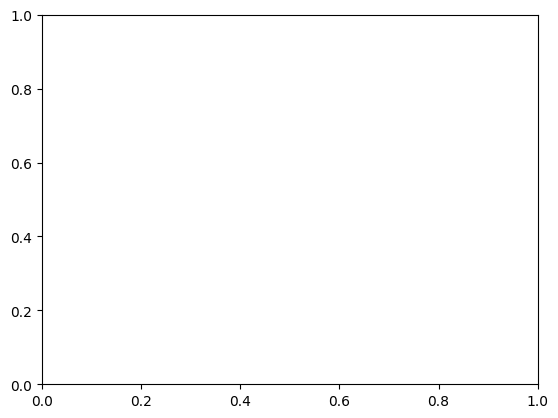

In [419]:
data = pdf.filter( variable=["Primary Energy|renewable|solar",
                                            "Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs, region = 'Canada')

data.plot.stack(title = 'Primary Energy by fuel - Baseline Scenario')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [492]:
i_feed = ['Useful Energy|i_feed|ethanol_fs|M1', 'Useful Energy|i_feed|gas_fs|M1',
         'Useful Energy|i_feed|loil_fs|M1', 'Useful Energy|i_feed|methanol_fs|M1']

transport = ['Useful Energy|transport|coal_trp|M1',
            'Useful Energy|transport|elec_trp|M1',
            'Useful Energy|transport|eth_fc_trp|M1',
            'Useful Energy|transport|eth_ic_trp|M1',
            'Useful Energy|transport|foil_trp|M1',
            'Useful Energy|transport|gas_trp|M1',
            'Useful Energy|transport|h2_fc_trp|M1',
            'Useful Energy|transport|loil_trp|M1',
            'Useful Energy|transport|meth_fc_trp|M1',
            'Useful Energy|transport|meth_ic_trp|M1']


i_spec = ['Useful Energy|i_spec|h2_fc_I|M1',
          'Useful Energy|i_spec|sp_coal_I|M1',
          'Useful Energy|i_spec|sp_el_I|M1',
          'Useful Energy|i_spec|sp_eth_I|M1',
          'Useful Energy|i_spec|sp_liq_I|M1',
          'Useful Energy|i_spec|sp_meth_I|M1']

i_therm =   ['Useful Energy|i_therm|biomass_i|M1',
            'Useful Energy|i_therm|coal_i|M1',
            'Useful Energy|i_therm|elec_i|M1',
            'Useful Energy|i_therm|eth_i|M1',
            'Useful Energy|i_therm|foil_i|M1',
            'Useful Energy|i_therm|gas_i|M1',
            'Useful Energy|i_therm|h2_fc_I|M1',
            'Useful Energy|i_therm|h2_i|M1',
            'Useful Energy|i_therm|heat_i|M1',
            'Useful Energy|i_therm|hp_el_i|M1',
            'Useful Energy|i_therm|hp_gas_i|M1',
            'Useful Energy|i_therm|loil_i|M1',
            'Useful Energy|i_therm|meth_i|M1',
            'Useful Energy|i_therm|solar_i|M1']
rc_spec = ['Useful Energy|rc_spec|h2_fc_RC|M1',
          'Useful Energy|rc_spec|sp_el_RC|M1']

rc_therm = ['Useful Energy|rc_therm|biomass_rc|M1',
            'Useful Energy|rc_therm|coal_rc|M1',
            'Useful Energy|rc_therm|eth_rc|M1',
            'Useful Energy|rc_therm|foil_rc|M1',
            'Useful Energy|rc_therm|gas_rc|M1',
            'Useful Energy|rc_therm|h2_fc_RC|M1',
            'Useful Energy|rc_therm|h2_rc|M1',
            'Useful Energy|rc_therm|heat_rc|M1',
            'Useful Energy|rc_therm|hp_el_rc|M1',
            'Useful Energy|rc_therm|hp_gas_rc|M1',
            'Useful Energy|rc_therm|loil_rc|M1',
            'Useful Energy|rc_therm|meth_rc|M1',
            'Useful Energy|rc_therm|solar_rc|M1']

biom = ['Useful Energy|non-comm|biomass_nc|M1']

In [493]:
df_useful = pyam_df.copy()
# df_useful.aggregate(
#     "Useful Energy|non-Commercial biomass",
#     components=biom,
#     append=True
# )

df_useful.aggregate(
    "residential/commercial thermal",
    components=rc_therm,
    append=True
)

df_useful.aggregate(
    "residential/commercial specific",
    components=rc_spec,
    append=True
)

df_useful.aggregate(
    "industrial thermal",
    components=i_therm,
    append=True
)

df_useful.aggregate(
    "industrial specific",
    components=i_spec,
    append=True
)

df_useful.aggregate(
    "industrial feedstock",
    components=i_feed,
    append=True
)

df_useful.aggregate(
    "transport",
    components=i_therm,
    append=True
)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

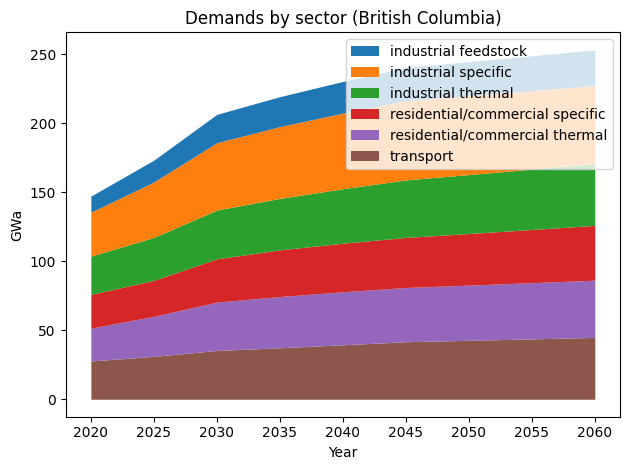

In [498]:
data = df_useful.filter( variable=[
    "non-Commercial biomass",
    "residential/commercial thermal",
    "residential/commercial specific",
    "industrial thermal",
    "industrial specific",
    "industrial feedstock",
    "transport"],
              year = plotyrs, region = 'BritishColumbia')


data.plot.stack(title = 'Demands by sector (British Columbia)', legend={"loc": "outside right"})
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [426]:
cement = ['Emissions|CO2|cement_CO2|M1']
coal = ['Emissions|CO2|coal_extr_ch4|M1',
        'Emissions|CO2|coal_extr|M1',
        'Emissions|CO2|coal_imp|M1']
foil = ['Emissions|CO2|foil_imp|M1']
gas = ['Emissions|CO2|gas_extr_1|M1',
        'Emissions|CO2|gas_extr_2|M1',
        'Emissions|CO2|gas_extr_3|M1',
        'Emissions|CO2|gas_extr_4|M1',
        'Emissions|CO2|gas_extr_5|M1',
        'Emissions|CO2|gas_extr_6|M1'
        ]
lignite = ['Emissions|CO2|lignite_extr|M1']
loil = ['Emissions|CO2|loil_imp|M1']
meth_ccs = ['Emissions|CO2|meth_coal_ccs|M1']
oil = ['Emissions|CO2|oil_extr_1_ch4|M1',
    'Emissions|CO2|oil_extr_1|M1',
    'Emissions|CO2|oil_extr_2_ch4|M1',
    'Emissions|CO2|oil_extr_2|M1',
    'Emissions|CO2|oil_extr_3_ch4|M1',
    'Emissions|CO2|oil_extr_3|M1',
    'Emissions|CO2|oil_extr_4_ch4|M1',
    'Emissions|CO2|oil_extr_4|M1',
    'Emissions|CO2|oil_extr_5|M1',
    'Emissions|CO2|oil_extr_6|M1',
    'Emissions|CO2|oil_extr_7|M1']

oil_trade = ['Emissions|CO2|foil_imp|M1',
             'Emissions|CO2|loil_exp|M1',
            'Emissions|CO2|loil_imp|M1',
             'Emissions|CO2|oil_imp|M1']
       
gas_trade = ['Emissions|CO2|LNG_exp|M1',
            'Emissions|CO2|LNG_imp|M1',
            'Emissions|CO2|gas_imp|M1']
            #'Emissions|CO2|LNG_exp|M1']

In [427]:
df_emis_b = pyam_df.filter(variable = 'Emissions|CO2|*',year = plotyrs)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [ ]:
df_emis_b.to_csv('emissions.csv')

In [428]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

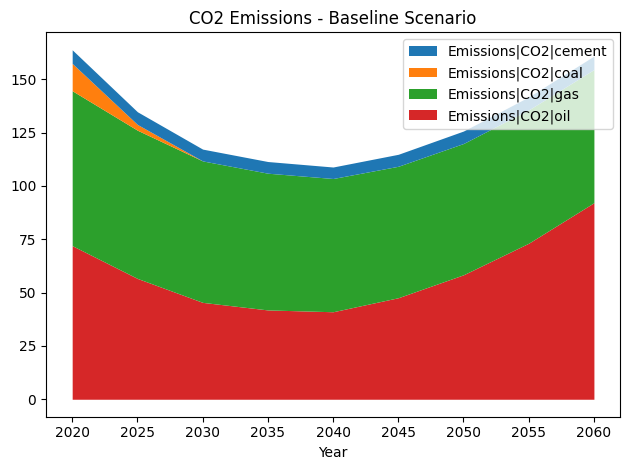

In [433]:
data = df_emis.filter( variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement"],
    # "Emissions|CO2|oil trade",
    # "Emissions|CO2|gas trade"],
              year = plotyrs, region = 'Canada')

data.plot.stack(title = 'CO2 Emissions - Baseline Scenario')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [ ]:
df_emis.aggregate('Emissions|*').timeseries()

In [523]:

coal = ['Total Costs|coal_adv',
        'Total Costs|coal_adv_ccs',
        'Total Costs|coal_bal',
        'Total Costs|coal_exp',
        'Total Costs|coal_extr',
        'Total Costs|coal_extr_ch4',
        'Total Costs|coal_gas',
        'Total Costs|coal_hpl',
        'Total Costs|coal_i',
        'Total Costs|coal_imp',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
        'Total Costs|coal_rc',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
       'Total Costs|coal_t_d',
       'Total Costs|syn_liq',
        'Total Costs|meth_coal',
       'Total Costs|lignite_extr']
biomass = ['bio_hpl', 'bio_ppl',
          'Total Costs|liq_bio']


elec = ['Total Costs|elec_exp',
        'Total Costs|elec_i',
        'Total Costs|elec_imp',
        'Total Costs|elec_t_d',
        'Total Costs|elec_trp']

oil = ['Total Costs|foil_i',
    'Total Costs|foil_imp',
    'Total Costs|foil_ppl',
    'Total Costs|oil_extr_1'
    'Total Costs|oil_extr_1_ch4'
    'Total Costs|oil_extr_2',
    'Total Costs|oil_extr_3',
    'Total Costs|oil_extr_4',
    'Total Costs|oil_extr_5',
    'Total Costs|oil_extr_6',
    'Total Costs|oil_extr_7',
    'Total Costs|oil_extr_2_ch4',
    'Total Costs|oil_extr_3_ch4',
    'Total Costs|loil_cc',
    'Total Costs|loil_ppl']
gas = ['Total Costs|gas_bal',
    'Total Costs|gas_bio',
    'Total Costs|gas_cc',
    'Total Costs|gas_cc_ccs',
    'Total Costs|gas_ct',
    'Total Costs|gas_extr_1',
    'Total Costs|gas_extr_2',
    'Total Costs|gas_extr_3',
    'Total Costs|gas_extr_4',
    'Total Costs|gas_extr_5',
    'Total Costs|gas_extr_6',
    'Total Costs|gas_extr_mpen',
    'Total Costs|gas_fs',
    'Total Costs|gas_hpl',
    'Total Costs|gas_i',
    'Total Costs|gas_imp',
    'Total Costs|gas_ppl',
    'Total Costs|gas_rc',
    'Total Costs|gas_t_d',
    'Total Costs|gas_t_d_ch4',
    'Total Costs|gas_trp',
      'Total Costs|igcc']

geo_ppl = ['Total Costs|geo_hpl','Total Costs|geo_ppl']

solar = ['Total Costs|solar_i',
        'Total Costs|solar_pv_ppl',
        'Total Costs|solar_rc',
        'Total Costs|solar_th_ppl']

wind = ['Total Costs|wind_curtailment1',
'Total Costs|wind_curtailment2',
'Total Costs|wind_curtailment3',
'Total Costs|wind_ppf',
'Total Costs|wind_ppl']

hydro = ['Total Costs|hydro_hc',
'Total Costs|hydro_lc']

nuclear = ['Total Costs|nuc_lc']


In [544]:
df_cost = pyam_df.copy()


df_cost.aggregate(
    "Total Costs|coal",
    components=coal,
    append=True
)

df_cost.aggregate(
    "Total Costs|biomass",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|electricity",
    components=elec,
    append=True
)

df_cost.aggregate(
    "Total Costs|oil",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|gas",
    components=gas,
    append=True
)

df_cost.aggregate(
    "Total Costs|geothermal",
    components=geo_ppl,
    append=True
)

df_cost.aggregate(
    "Total Costs|solar",
    components=solar,
    append=True
)

df_cost.aggregate(
    "Total Costs|wind",
    components=wind,
    append=True
)

df_cost.aggregate(
    "Total Costs|hydro",
    components=hydro,
    append=True
)
df_cost.aggregate(
    "Total Costs|nuclear",
    components=nuclear,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

In [502]:
data.unit

['']

In [531]:
df_cost.timeseries()

2010  \
model            scenario       region  variable                          unit         
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp                0.0   
                                        Capacity Addition|adipic_thermal         0.0   
                                        Capacity Addition|ammonia_secloop        0.0   
                                        Capacity Addition|bio_hpl                0.0   
                                        Capacity Addition|bio_hpl__air           0.0   
...                                                                              ...   
                                Yukon   vom cost|wind_cv2                        0.0   
                                        vom cost|wind_cv3                        0.0   
                                        vom cost|wind_cv4                        0.0   
                                        vom cost|wind_ppf                        0.0   
                                        vom cost|wind_ppl                        0.0   

                                                                                2015  \
model            scenario       region  variable                          unit         
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp                0.0   
                                        Capacity Addition|adipic_thermal         0.0   
                                        Capacity Addition|ammonia_secloop        0.0   
                                        Capacity Addition|bio_hpl                0.0   
                                        Capacity Addition|bio_hpl__air           0.0   
...                                                                              ...   
                                Yukon   vom cost|wind_cv2                        0.0   
                                        vom cost|wind_cv3                        0.0   
                                        vom cost|wind_cv4                        0.0   
                                        vom cost|wind_ppf                        0.0   
                                        vom cost|wind_ppl                        0.0   

                                                                                    2020  \
model            scenario       region  variable                          unit             
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp               0.000000   
                                        Capacity Addition|adipic_thermal        0.000193   
                                        Capacity Addition|ammonia_secloop       0.000000   
                                        Capacity Addition|bio_hpl               0.082997   
                                        Capacity Addition|bio_hpl__air          0.000000   
...                                                                                  ...   
                                Yukon   vom cost|wind_cv2                       0.000000   
                                        vom cost|wind_cv3                       0.000000   
                                        vom cost|wind_cv4                       0.000000   
                                        vom cost|wind_ppf                       0.000000   
                                        vom cost|wind_ppl                       0.000000   

                                                                                   2025  \
model            scenario       region  variable                          unit            
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp               0.00000   
                                        Capacity Addition|adipic_thermal        0.00031   
                                        Capacity Addition|ammonia_secloop       0.00000   
                                        Capacity Addition|bio_hpl               0.00000   
                                        Capacit

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

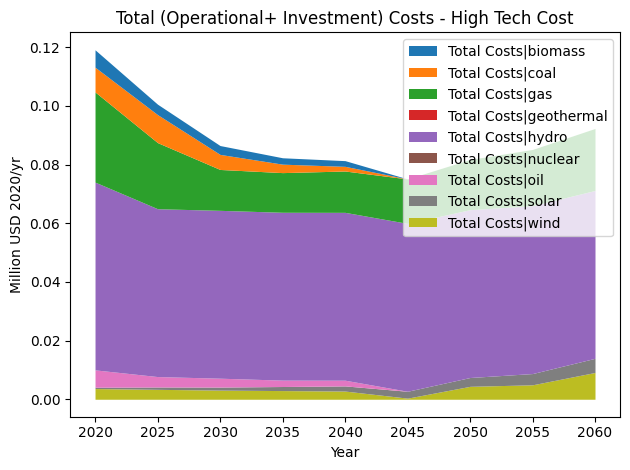

In [545]:
data = df_cost.filter( variable=
    ["Total Costs|coal","Total Costs|biomass",
    # "Total Costs|electricity",
    "Total Costs|oil",
    "Total Costs|gas",
    "Total Costs|geothermal",
    "Total Costs|solar",
    "Total Costs|wind",
    "Total Costs|hydro",
    "Total Costs|nuclear"],
              year = plotyrs, region = 'Canada')
data.convert_unit("", to="million USD/yr", factor=0.000001, inplace = True)

data.plot.stack(title = 'Total (Operational+ Investment) Costs - High Tech Cost')
plt.legend(loc=1)
plt.ylabel('Million USD 2020/yr')
plt.tight_layout()

plt.show()


Now making another scenario cloned from baseline to add other policies. 

Policy No. 1
Baseline - NDC 
Implement Canada's commitments 


In [438]:
technologies = [
    # "hp_el_rc",
    # "hp_gas_rc",
    # "hp_el_i",
    # "hp_gas_i",
    # "solar_pv_RC",
    # "solar_curtailment1",
    # "solar_cv1",
    "solar_pv_ppl",
    # "solar_res1",
    "solar_th_ppl",
    # "csp_sm3_res",
    # "csp_sm3_ppl",
    # "csp_sm1_res",
    # "csp_sm1_ppl",
    # "wind_curtailment1",
    "wind_cv1",
    "wind_ppl",
    "wind_res1",
    "wind_ppf",
    "wind_ref1",
    "stor_ppl",
    "h2_elec",
    "h2_smr_ccs",
    "bio_istig_ccs",
    "h2_mix",
    "glb_lh2_imp",
    "h2_bio_ccs",
    "h2_co2_scrub",
    "h2_coal",
    "h2_coal_ccs",
    "h2_liq",
    "h2_smr",
    "h2_t/d",
    "h2b_co2_scrub",
    # "lh2_bal",
    "lh2_exp",
    "lh2_imp",
    "lh2_regas",
    "lh2_t/d",
    # "h2_i",
    # "h2_fc_I",
    # "h2_rc",
    # "h2_fc_RC",
    # "h2_fc_trp",
    "LH2_bunker",
    "coal_adv_ccs",
    "gas_cc_ccs",
    "igcc_ccs",
    "cement_co2scr",
    "eth_bio_ccs",
    "liq_bio_ccs",
    "meth_coal_ccs",
    "meth_ng_ccs",
    "syn_liq_ccs",
    "cfc_co2scr"
]


In [440]:
msgbas = msgbas.clone(modelName, 'low_cost,
                     keep_solution=False)
df_inv = msgbas.par('inv_cost')
df_var = msgbas.par('var_cost')
df_fix = msgbas.par('fix_cost')
df_inv.loc[df_inv['technology'].isin(technologies), 'value'] *=0.9
df_var.loc[df_var['technology'].isin(technologies), 'value'] *=0.9
df_fix.loc[df_fix['technology'].isin(technologies), 'value'] *=0.9

msgbas.check_out()
msgbas.add_par('inv_cost', df_inv)
msgbas.add_par('fix_cost', df_fix)
msgbas.add_par('var_cost', df_var)
msgbas.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgbas.model + '__' + msgbas.scenario + '__v' + str(msgbas.version)
msgbas.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

In [451]:
msghigh = msg.clone(modelName, 'high_cost',
                     keep_solution=False)
df_inv = msghigh.par('inv_cost')
df_var = msghigh.par('var_cost')
df_fix = msghigh.par('fix_cost')
df_inv.loc[df_inv['technology'].isin(technologies), 'value'] *=1.1
df_var.loc[df_var['technology'].isin(technologies), 'value'] *=1.1
df_fix.loc[df_fix['technology'].isin(technologies), 'value'] *=1.1

msghigh.check_out()
msghigh.add_par('inv_cost', df_inv)
msghigh.add_par('fix_cost', df_fix)
msghigh.add_par('var_cost', df_var)
msghigh.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msghigh.model + '__' + msghigh.scenario + '__v' + str(msghigh.version)
msghigh.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

message_ix.models - INFO: Use CPLEX options {'advind': 0, 'lpmethod': '4', 'threads': 4, 'epopt': 1e-06}


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 04/18/24 02:10:45 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__high_cost__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__high_cost__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__high_cost__v1.gdx
Licensee: Small MUD - 5 User License         

2024-04-17 23:11:27,121 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-04-17 23:11:27,134 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [ ]:
from message_ix.reporting import Reporter
from update_units import unit_correction
import numpy as np
unit_correct = False  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

if unit_correct:
    msg = msg.clone(keep_solution=False)
    unit_correction(mp, msg)
    caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)
    # Solving the model
    msg.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

#%% Generating reporter
rep = Reporter.from_scenario(msgbas)
report = rep.get('message:default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()

    # Plotted years
years = msgbas.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
c = report_df.select_dtypes(include=[np.number]) * 8.76
report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = out_flows.append(in_flows)

In [ ]:
report_df.to_csv('MESSAGE_CANADA_baselinendc.csv')

In [ ]:
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('emis', 'Emissions', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)

In [ ]:
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
pdf = pyam_df.copy()

In [ ]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

In [ ]:
pdf.filter(variable = 'Primary Energy|oil').timeseries()

In [ ]:
pdf.filter( variable=["Primary Energy|renewable|solar",
                                            #"Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs).stack_plot(total=True,
                                        title = 'Primary Energy by fuel - Baseline Scenario')

In [ ]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

In [ ]:
df_emis.timeseries()

In [ ]:
df_emis.filter( variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement",
    "Emissions|CO2|oil trade",
    "Emissions|CO2|gas trade"],
              year = plotyrs,region = 'Canada').stack_plot(total=True,
                                         title = 'CO2 Emissions - Baseline Scenario')

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('MESSAGE_CANADA_baselinendc.csv')

In [ ]:
df['Model'].replace('CD_Links_SSP2_R14', 'MESSAGEix-Canada', inplace=True)

In [ ]:
df.head()

In [ ]:
df.to_csv('MESSAGE_CANADA_v1.csv')

In [ ]:
import pandas as pd

In [ ]:
iso = 'CAN'

In [ ]:
# SSP GDP data
ssp_gdp_df = pd.read_excel( str('OECD_SSP_GDP_PPP.xlsx'),
        'OECD_SSP_GDP_PPP',
        header = 0)
ssp_gdp_df = ssp_gdp_df.loc[ (  ssp_gdp_df.Region == iso ) ].reset_index(drop=True)

# SSP population data

ssp_pop_df = pd.read_excel(str('OECD_SSP_POP.xlsx'),
        'OECD_SSP_POP',
        header = 0)
ssp_pop_df = ssp_pop_df.loc[ (  ssp_pop_df.Region == iso  ) ].reset_index(drop=True)

In [ ]:
ssp_pop_df['Scenario'] = ssp_pop_df['Scenario'].str.replace('_v9_130325', '')
ssp_gdp_df['Scenario'] = ssp_gdp_df['Scenario'].str.replace('_v9_130325', '')

In [ ]:
ssp_gdp_df

In [ ]:
import pyam
import matplotlib.pyplot as plt
import pyam

pop_df = pyam.IamDataFrame(ssp_pop_df)
gdp_df = pyam.IamDataFrame(ssp_gdp_df)

In [ ]:
pop_df.head()

In [ ]:
pop_df.plot(color='scenario', title='Population Projections of Canada across SSPs')

In [ ]:
gdp_df.plot(color='scenario', title='GDP Projections of Canada across SSPs')

In [ ]:
mp.add_unit('tCO2/kWa')
mp.add_unit('MtCO2')

In [ ]:
msgbas.set('type_emission')

In [ ]:

msgbas.add_par('bound_emission', ['Canada', 'TCE', 'all', 'cumulative'],
             value=700., unit='MtCO2')

In [ ]:
msgbas.commit('adding emissions bound')

In [ ]:
msgbas.solve()

In [ ]:
msgbas.scenario

In [ ]:
msgbas.par('bound_emission')

In [ ]:
msgCT = msgbas.clone(modelName, 'carbon_bound_by_year','introducing a carbon tax',
                             keep_solution=False)
msgCT.check_out()

In [ ]:
emissions = msgCT.var('EMISS')
emissions

In [ ]:

emission_prices_by_year = msg.var('PRICE_EMISSION')
emission_prices_by_year

In [ ]:

scen_tax = base.clone(model, 'carbon_tax','introducing a carbon tax',
                      keep_solution=False)
scen_tax.check_out()

In [ ]:
years

In [ ]:

base_tax_emission = {
    'node': 'Canada',
    'type_year': years,
    'type_tec': 'all',
    'unit': 'USD/tCO2',
    'type_emission': 'GHG',
    'value': emission_prices.set_index('year').lvl
}

In [ ]:


# in case you need to add the new unit to the platform
mp.add_unit('USD/tCO2')

tax_emission = make_df(base_tax_emission)
scen_tax.add_par('tax_emission', tax_emission)
scen_tax.par('tax_emission')

In [ ]:

scen_tax.commit(comment='setting taxes on emissions')

In [ ]:
scen_tax.var('EMISS', {'node': 'Westeros'})